<a href="https://colab.research.google.com/github/Tdhairya2325/UAV-Intelligence-System/blob/main/notebooks/01_data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import glob

PROJECT_DIR = "/content/drive/MyDrive/UAV-Intelligence-System"

RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")

TRAIN_DIR = os.path.join(RAW_DIR, "VisDrone2019-DET-train")

VAL_DIR = os.path.join(RAW_DIR, "VisDrone2019-DET-val")

print("Project directory:", PROJECT_DIR)
print("Raw dataset directory:", RAW_DIR)
print("Training directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)

Project directory: /content/drive/MyDrive/UAV-Intelligence-System
Raw dataset directory: /content/drive/MyDrive/UAV-Intelligence-System/data/raw
Training directory: /content/drive/MyDrive/UAV-Intelligence-System/data/raw/VisDrone2019-DET-train
Validation directory: /content/drive/MyDrive/UAV-Intelligence-System/data/raw/VisDrone2019-DET-val


In [3]:
for root, dirs, files in os.walk(RAW_DIR):
    level = root.replace(RAW_DIR, "").count(os.sep)

    if level < 3:
        print("    " * level + os.path.basename(root) + "/")

raw/
    VisDrone2019-DET-train/
        images/
        annotations/
    VisDrone2019-DET-val/
        images/
        annotations/


In [4]:
def inspect_dataset(dataset_dir):

    image_dir = os.path.join(dataset_dir, "images")
    annotation_dir = os.path.join(dataset_dir, "annotations")

    images = glob.glob(os.path.join(image_dir, "*.jpg"))
    annotations = glob.glob(os.path.join(annotation_dir, "*.txt"))

    print("Dataset:", os.path.basename(dataset_dir))
    print("Total images:", len(images))
    print("Total annotation files:", len(annotations))
    print("-" * 40)


inspect_dataset(TRAIN_DIR)
inspect_dataset(VAL_DIR)

Dataset: VisDrone2019-DET-train
Total images: 6471
Total annotation files: 6471
----------------------------------------
Dataset: VisDrone2019-DET-val
Total images: 548
Total annotation files: 548
----------------------------------------


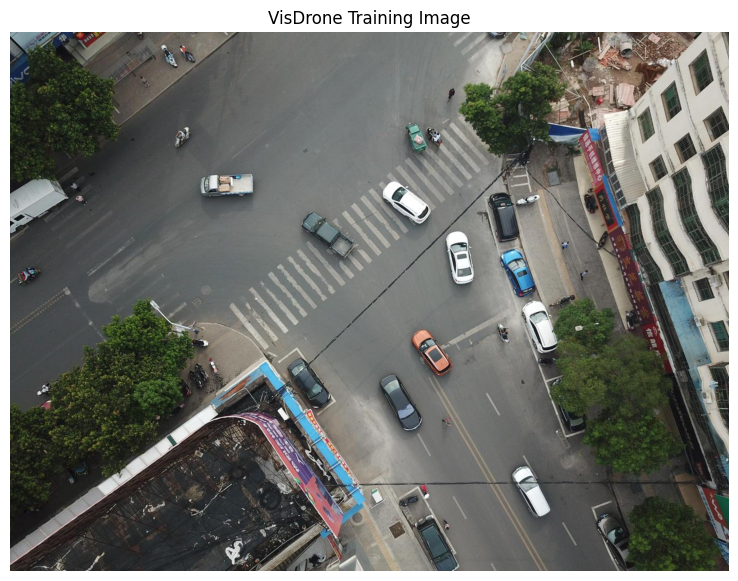

Image shape: (1050, 1400, 3)


In [5]:
import cv2
import matplotlib.pyplot as plt

train_images = glob.glob(
    os.path.join(TRAIN_DIR, "images", "*.jpg")
)

image_path = train_images[0]

image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image)
plt.title("VisDrone Training Image")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)

In [6]:
import pandas as pd

annotation_files = glob.glob(
    os.path.join(TRAIN_DIR, "annotations", "*.txt")
)

sample_annotation = annotation_files[0]

columns = [
    "left",
    "top",
    "width",
    "height",
    "score",
    "category",
    "truncation",
    "occlusion"
]

df = pd.read_csv(
    sample_annotation,
    header=None,
    names=columns
)

print(df.head())
print("\nTotal objects in this image:", len(df))

   left  top  width  height  score  category  truncation  occlusion
0   842  950     13      19      1         1           0          0
1   805  897     10      13      1         1           0          0
2   953  577     17      18      1         2           0          0
3  1110  460     16      25      1         1           0          0
4  1073  405     15      21      1         1           0          1

Total objects in this image: 52
